# Perceptron AND operator

A comparison of the reference weight-update rule and a signed-error correction on the complete two-input AND truth table.

## Data and model

The four binary input combinations have targets [0, 0, 0, 1]. The decision rule uses a fixed threshold of 1, equivalent to a fixed bias of −1. Initial weights are [0, 0] and the baseline learning rate is 0.1. All four combinations are used for training; accuracy therefore measures truth-table agreement, not held-out generalisation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('NumPy:', np.__version__)


NumPy: 2.4.4


In [2]:
X=np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
y=np.array([0,0,0,1])

def train_and(initial=(0,0), learning_rate=0.1, signed=False, max_epochs=100):
    weights=np.array(initial,dtype=float)
    history=[]
    for epoch in range(1,max_epochs+1):
        mistakes=0
        for inputs,target in zip(X,y):
            prediction=int(inputs @ weights >= 1)
            error=int(target-prediction)
            mistakes+=abs(error)
            update=error if signed else abs(error)
            weights+=learning_rate*inputs*update
        history.append(mistakes)
        if mistakes==0:
            break
    predictions=(X @ weights >= 1).astype(int)
    return weights,predictions,history

weights,predictions,history=train_and()
display(pd.DataFrame({'x₁':X[:,0].astype(int),'x₂':X[:,1].astype(int),'Target':y,'Score':X@weights,'Prediction':predictions}))
print('Final weights:',weights)
print('Passes including final zero-error pass:',len(history))
print('Accuracy:',np.mean(predictions==y))
assert np.allclose(weights,[0.5,0.5]) and np.array_equal(predictions,y)


x₁,x₂,Target,Score,Prediction
0,0,0,0.0,0
0,1,0,0.5,0
1,0,0,0.5,0
1,1,1,1.0,1


Final weights: [0.5 0.5]
Passes including final zero-error pass: 6
Accuracy: 1.0


## Update-rule sensitivity

The reference update uses `abs(target − prediction)`. This can increase weights after a false negative but cannot decrease them after a false positive. The corrected update uses the signed residual: `w ← w + η(target − prediction)x`. A maximum of 100 passes bounds every run. The baseline's six passes include five update passes and one confirmation pass.

Case,Passes,Zero-error pass,w₁,w₂,Accuracy
Reference baseline,6,True,0.50,0.50,1.0
Reference high initial weights,100,False,11.25,11.25,0.5
Signed high initial weights,4,True,0.95,0.95,1.0
Signed rate 0.05,12,True,0.55,0.55,1.0
Signed rate 0.2,4,True,0.60,0.60,1.0


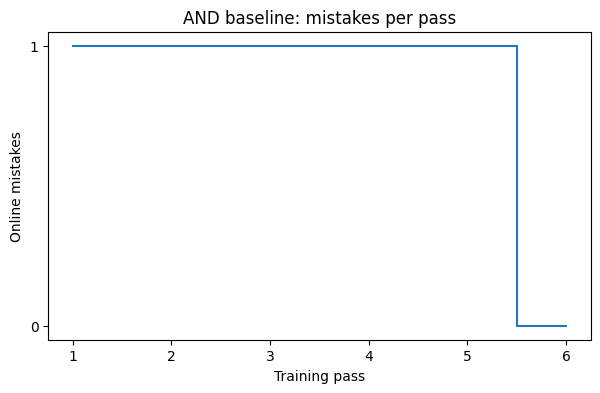

In [3]:
comparisons=[]
for label,initial,rate,signed in [
    ('Reference baseline',(0,0),0.1,False),
    ('Reference high initial weights',(1.25,1.25),0.1,False),
    ('Signed high initial weights',(1.25,1.25),0.1,True),
    ('Signed rate 0.05',(0,0),0.05,True),
    ('Signed rate 0.2',(0,0),0.2,True)]:
    w,p,h=train_and(initial,rate,signed)
    comparisons.append({'Case':label,'Passes':len(h),'Zero-error pass':h[-1]==0,'w₁':w[0],'w₂':w[1],'Accuracy':np.mean(p==y)})
display(pd.DataFrame(comparisons).round(4))
fig,ax=plt.subplots(figsize=(7,4))
ax.step(np.arange(1,len(history)+1),history,where='mid')
ax.set(xlabel='Training pass',ylabel='Online mistakes',title='AND baseline: mistakes per pass',yticks=[0,1]);plt.show()


## Interpretation

AND is linearly separable. The baseline weights [0.5, 0.5] classify all four combinations correctly, with [1, 1] exactly on the inclusive threshold. The high-weight comparison exposes the limitation of absolute-error updates: false positives cause further increases. Signed updates restore the direction needed to correct those errors. Convergence observed for these cases is not a guarantee for arbitrary data, learning rates or a model with a fixed bias.

## Provenance and reproducibility

Adapted from the reference notebooks credited to Dr Mike Lakoju. The implementations retain the reference inputs and model structure; corrections and extensions are identified above. All data are defined in code. Cells were executed sequentially in an independent Python namespace, with outputs embedded. Analysis and editorial preparation used AI assistance.
